# ЛР 1. Начало работы с ML-проектом: формализация задачи и первичный анализ данных
<!-- В VSCode есть специальное расширение для генерации интерактивного оглавления -->
<!-- Желательно в оглавлении сохранить нумерацию пунктов -->
<!-- Правилом хорошего тона является создание интерактивных заголовков пунктов и подпунктов, которые ведут на оглавление -->

**Table of contents**<a id='toc0_'></a>

## Описание задачи
**1. Предметная область и боли заказчика:**
Заказчиком выступает король Эйгон I Таргариен, который строит Красный замок. Крепость должна выдерживать осады и быть максимально надежной. Мейстеры провели испытания строительной смеси. 

*Боль заказчика (Эйгона):* Он не хочет слепо доверять мастерам и желает знать наверняка: от чего сильнее зависит прочность стены — от самой смеси или от времени её выдержки? Строительство нельзя тормозить просто так, поэтому нужно обосновать, имеет ли смысл долго ждать усадки.

*Суть гипотезы Эйгона:* Влияет ли время на итоговую прочность стен так же сильно (или даже сильнее), чем состав смеси?

**2. Постановка ML-задачи:**
Перед нами стоит задача **регрессии** (Regression), так как целевая переменная (прочность на сжатие) является непрерывной вещественной величиной. Дополнительной (и главной) задачей является **анализ важности признаков (гипотеза Эйгона)**, чтобы ответить на вопрос короля о влиянии состава смеси против влияния времени.

**3. Объект задачи:**
Объектом исследования является отдельный образец строительной смеси, для которого известен состав, время выдержки и итоговая прочность.

**4. Образ выходного результата модели:**
На выходе модель должна предсказывать точное число — прочность материала на сжатие. Также результатом работы станет аналитический вывод о том, какой фактор вносит наибольший вклад в прочность.

`ячейки для описания исходных данных`
<!-- 
    В этой и последующих ячейках предлагается описать исходные данные, а также сопутствующую информацию:
    1. таблицу с семантикой данных, а также типами данных столбцов (ожидаемый тип, а не фактический, которые мы получаем при чтении данных) в формате MD (кодом не надо выводить таблички)
    2. формулы прикладной области (с указанием, какие формулы можно использовать, а какие -- нет)
-->

## Описание исходных данных и их семантика (Data Understanding)

Набор данных представляет собой результаты испытаний образцов строительной смеси. Все признаки являются числовыми (вещественными).

| Название признака (столбец) | Семантика (описание) | Ожидаемый тип данных | Роль |
| :--- | :--- | :--- | :--- |
| **Cement** | Количество цемента в смеси (кг/м³) | `float` | Входной |
| **Blast Furnace Slag** | Доменной шлак (кг/м³) | `float` | Входной |
| **Fly Ash** | Зола-унос (кг/м³) | `float` | Входной |
| **Water** | Количество воды (кг/м³) | `float` | Входной |
| **Superplasticizer** | Суперпластификатор (кг/м³) | `float` | Входной |
| **Coarse Aggregate** | Крупный заполнитель / щебень (кг/м³) | `float` | Входной |
| **Fine Aggregate** | Мелкий заполнитель / песок (кг/м³) | `float` | Входной |
| **Age** | Время выдержки материала (в днях) | `float` | Входной |
| **Concrete compressive strength** | Прочность на сжатие (МПа) | `float` | **Целевой** |

`Доменный шлак` — это побочный продукт, который образуется при выплавке чугуна в доменной печи. Проще говоря, это «отход» металлургического производства, который раньше просто выбрасывали, а сейчас активно используют в строительстве. 

`Зола-унос (или летучая зола)` — это тонкодисперсный порошок, который образуется при сжигании твёрдого топлива, чаще всего угля, на тепловых электростанциях.

`Суперпластификатор` — это такая «волшебная» добавка в бетонную смесь, которая делает её гораздо более пластичной и текучей, чем обычно. При этом не нужно добавлять лишнюю воду, чтобы смесь было легко заливать.

## Формулы прикладной области

### Водовяжущее отношение 
— это отношение массы воды к массе вяжущего вещества после затворения смеси. Этот параметр используется в строительстве, в частности при работе с бетонными смесями, где часть цемента может заменяться минеральными добавками (например, золой-уноса, доменным гранулированным шлаком, микрокремнезёмом). 

Новый признак (Binder): $Binder = Cement + Slag + Fly Ash$

Новый признак (W/B): $W/B = \frac{Water}{Binder}$

---
### Формула Боломея-Скрамтаева
Для бетонов средней и высокой прочности закон Абрамса часто заменяют линейной формулой Боломея-Скрамтаева, которая использует обратное отношение (цемент к воде):$$R = A \cdot R_c \cdot \left( \frac{C}{W} - 0.5 \right)$$Где $C/W$ — цементно-водное отношение.Новый признак: $\frac{Cement}{Water}$ или $\frac{Binder}{Water}$. 

Поскольку $A$ и $R_c$ для конкретной выборки являются константами (или скрытыми параметрами), задача алгоритма — самостоятельно подобрать такие веса, которые заменят эти неизвестные множители.

`справка` $R_c$ (Активность или марка цемента): Это физико-механическая характеристика самого цемента (например, цемент марки М400 или М500). $A$ (Коэффициент качества): Это эмпирический коэффициент, зависящий от качества заполнителей (щебня и песка). 

---
### Логарифмический закон роста прочности во времени 
— это эмпирическая зависимость, которая приближённо описывает процесс увеличения прочности материалов (например, бетона на основе цементного вяжущего) с течением времени. 

`Суть закона`

Согласно этому закону, прочность материала сначала растёт интенсивно, а затем темп замедляется. Математически это выражается тем, что зависимость прочности от времени в обычном масштабе является логарифмической функцией, а в логарифмическом масштабе времени — линейной.

`Формула расчёта`

$$R_n = R_{28} \cdot \frac{\log(n)}{\log(28)}$$

где:
Rₙ — прочность бетона в возрасте n суток;
R₂₈ — прочность в возрасте 28 суток;

Новый признак: $Log\_Age = \log(Age)$

---

В строительстве (и в записях мейстеров) базовым правилом оценки прочности является **Закон Абрамса (Abrams' law)**. Он гласит, что прочность смеси обратно пропорциональна водоцементному отношению (отношению массы воды к массе цемента):

$$ S = \frac{A}{B^{W/C}} $$

Где:
* $S$ — прочность материала
* $W/C$ — отношение массы воды к массе цемента (признак Water разделить на признак Cement)
* $A$ и $B$ — константы, зависящие от внешних условий.

### Вывод: использование формул в ML-задаче

Опираясь на описанные выше физические законы прочности, мы должны четко разделить их применимость в рамках нашего ML-проекта:

**Что использовать НЕЛЬЗЯ:**
Нельзя применять формулу Боломея-Скрамтаева или закон Абрамса напрямую для аналитического (ручного) расчета целевой переменной (прочности на сжатие), подменяя тем самым модель машинного обучения. Эти эмпирические формулы идеализированы, они требуют знания скрытых коэффициентов (качество заполнителей $A$, истинная марка цемента $R_c$) и не умеют корректно учитывать влияние современных химических добавок (например, суперпластификатора). Алгоритм должен сам найти веса и зависимости.

**Что использовать МОЖНО:**
Можно (и нужно) использовать математическую **структуру** этих формул на этапе генерации новых признаков (Feature Engineering). Мы имеем полное право создать новые столбцы в нашем датасете, опираясь на физику процесса:
1. Водовяжущее отношение ($W/B$) или обратное ему ($Binder/Water$).
2. Логарифм возраста ($Log\_Age$).

`ячейки для создания и фиксации виртуального окружения`
<!-- 
    В этой и последующих ячейках предлагается зафиксировать информацию о виртуальном окружении, а именно:
    1. версию питона
    2. версию и список используемых библиотек
    3. основные и часто встречающиеся импорты (pandas, numpy, typing, warnings и т.д.)
    4. случайный сид (seed / random_state)
-->

In [1]:
!python --version # Версия Python

Python 3.12.1


In [2]:
!pip list # Список и версии библиотек

Package                                  Version
---------------------------------------- ------------------
accelerate                               1.13.0
aiofile                                  3.12.3
aiohappyeyeballs                         2.6.2
aiohttp                                  3.13.5
aiosignal                                1.4.0
alembic                                  1.18.4
altair                                   6.1.0
annotated-doc                            0.0.4
annotated-types                          0.7.0
anyio                                    4.13.0
asttokens                                3.0.1
attrs                                    26.1.0
Authlib                                  1.8.0
bcrypt                                   5.0.0
beartype                                 0.22.9
beautifulsoup4                           4.14.3
blinker                                  1.9.0
branca                                   0.8.2
bs4                                  


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Базовые библиотеки для работы с таблицами и массивами
import pandas as pd
import numpy as np

# Настройка предупреждений
import warnings
warnings.filterwarnings('ignore')

# Инструмент для разделения выборки
from sklearn.model_selection import train_test_split

# Фиксация случайного сида для воспроизводимости
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Предварительная обработка данных

## 1.1. Чтение и загрузка данных 

In [4]:
# Загрузка данных
df = pd.read_csv('data/game_of_thrones.csv', sep=';')

In [5]:
df.head(20)

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
0,540.0,0.0,0.0,NaN,2.5,1040.0,676.0,28.0,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,NaN,90.0,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365.0,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28.0,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28.0,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28.0,39.29


## 1.2. Первичный анализ данных

Первоначально необходимо проанализировать типы данных колонок датафрейма и проверить наличие пропущенных значений. Воспользуемся методом датафрейма `.info()`, который выводит сводную информацию об объекте. Дополнительно применим метод `.describe()` для оценки распределения (среднее, минимум, максимум, квартили) числовых признаков. 
Это поможет нам понять, готовы ли данные к делению на обучающую и тестовую выборки.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement kg/m^3                  968 non-null    float64
 1   Blast Furnace Slag kg/m^3      958 non-null    float64
 2   Fly Ash kg/m^3                 948 non-null    float64
 3   Water kg/m^3                   948 non-null    float64
 4   Superplasticizer kg/m^3        937 non-null    float64
 5   Coarse Aggregate kg/m^3        927 non-null    float64
 6   Fine Aggregate kg/m^3          906 non-null    float64
 7   Age day                        978 non-null    float64
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(9)
memory usage: 72.6 KB


1. **Типы данных:** Все 9 признаков корректно спарсились как вещественные числа (`float64`). Приведение типов не требуется, данные соответствуют заявленной семантике.

2. **Целевая переменная:** Признак `Concrete compressive strength` не имеет пропусков (1030 non-null из 1030). Это значит, что удаление строк из-за отсутствия целевой метки не потребуется.

3. **Наличие пропущенных значений:** Во всех входных признаках (от `Cement` до `Age`) присутствуют пропущенные значения (NaN), так как количество non-null значений везде меньше 1030. Следовательно, на этапе предварительной обработки будет необходимо применить стратегии заполнения пропусков. 

In [7]:
df.describe()

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
count,968.000000,958.000000,948.00000,948.000000,937.000000,927.000000,906.000000,978.000000,1030.000000
mean,280.409814,73.453758,53.48692,181.708228,6.202455,972.645847,773.029470,45.721881,35.817961
std,103.923736,86.313283,64.16564,21.642256,5.968103,78.112692,79.723362,63.983704,16.705742
min,102.000000,0.000000,0.00000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.00000,164.900000,0.000000,932.000000,733.250000,7.000000,23.710000
50%,272.700000,20.000000,0.00000,185.000000,6.400000,968.000000,778.500000,28.000000,34.445000
75%,350.000000,144.150000,118.30000,192.900000,10.200000,1029.400000,823.550000,56.000000,46.135000
max,540.000000,359.400000,200.10000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


1. **Все значения неотрицательны**, что полностью соответствует физическому смыслу признаков (масса и время).

2. **Разность масштабов:** Разброс значений колоссален (от единиц у `Superplasticizer` до тысяч у `Coarse Aggregate`). Это означает обязательную необходимость скалирования признаков на следующих этапах.

3. **Естественные нули:** Минимум (а иногда и медиана) у шлака, золы и пластификатора равен 0. Это нормально — данные добавки применяются не в каждой смеси.

4. **Специфика `Age`:** Медиана составляет 28 дней (стандарт тестирования), но есть сильный правый хвост (максимум 365). Такой разброс подтверждает нашу гипотезу о необходимости логарифмирования возраста для обучения. Разница между 1 и 28 днем огромная (там достигается 90% прочности), а дальше уже почти нулевая. Но машина этого не понимает и подумает, что за такое время прочность должна была вырасти в разы. Как спасает логарифм? В математике логарифмирование — это функция, которая "сжимает" большие числа и "растягивает" маленькие. Если мы вместо самих дней возьмем их логарифм, то машина увидит, что промежуток от 1 до 28 дней имеет большой вес, а огромный скачок от 180 до 365 дней превратится в маленький шажок.

In [8]:
df.nunique()

Cement kg/m^3                    273
Blast Furnace Slag kg/m^3        180
Fly Ash kg/m^3                   146
Water kg/m^3                     188
Superplasticizer kg/m^3          110
Coarse Aggregate kg/m^3          274
Fine Aggregate kg/m^3            280
Age day                           14
Concrete compressive strength    845
dtype: int64

1. В целевой переменной (`Concrete compressive strength`) целых 845 разных значений на 1030 строк. То есть мы предсказываем конкретное дробное число, а не просто категории "крепкий/хрупкий". Значит, это точно задача регрессии.

2. Во всех признаках состава смеси уникальных значений больше сотни. Категориальных колонок (текстовых или где всего 2-3 варианта ответа) у нас вообще нет. Получается шаг с кодированием категорий можно будет просто пропустить.

3. `Age` имеет всего 14 уникальных значений. Это значит, что бетон тестировали не каждый день подряд, а только в строго определенные контрольные дни (например, на 7-й, 14-й, 28-й день и т.д.), как это обычно и делают в лабораториях.

## 1.3. Разделение выборки на обучающую и тестовую выборки

In [9]:
y = df['Concrete compressive strength']
X = df.drop(['Concrete compressive strength'], axis = 1)

In [10]:
y

0       79.99
1       61.89
2       40.27
3       41.05
4       44.30
        ...  
1025    44.28
1026    31.18
1027    23.70
1028    32.77
1029    32.40
Name: Concrete compressive strength, Length: 1030, dtype: float64

In [11]:
X

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day
0,540.0,0.0,0.0,NaN,2.5,1040.0,676.0,28.0
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0
...,...,...,...,...,...,...,...,...
1025,276.4,NaN,90.3,179.6,8.9,NaN,768.3,28.0
1026,322.2,0.0,115.6,NaN,NaN,817.9,813.4,28.0
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28.0
1028,159.1,186.7,NaN,175.6,11.3,989.6,788.9,28.0


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, random_state=42, test_size=0.2)

In [13]:
print(f"Размер X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Размер X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Размер X_train: (824, 8), y_train: (824,)
Размер X_test:  (206, 8), y_test:  (206,)


## ЛР 2. Устранение проблем в данных: заполнение пропусков и кодирование категориальных признаков

## 2.1 Обработка вещественных признаков (заполнение пропусков)

Пропуски в данных у нас имеются, посмотрим их количество по колонкам:

In [14]:
df.isnull().sum()

Cement kg/m^3                     62
Blast Furnace Slag kg/m^3         72
Fly Ash kg/m^3                    82
Water kg/m^3                      82
Superplasticizer kg/m^3           93
Coarse Aggregate kg/m^3          103
Fine Aggregate kg/m^3            124
Age day                           52
Concrete compressive strength      0
dtype: int64

В целевых значениях пропусков не обнаружено. Доля пропусков в колонках не превышает 20%, соответственно будем не удалять, а пытаться заполнять. Для этого воспользуемся машинным и статистическим подходом и сравним результаты.

### Статистические подходы

Долго думать не будем и просто бахнем медиану, в контексте нашей бизнес задачи звучит вполне разумно

In [15]:
xtrain_stat = X_train.copy()
xtest_stat = X_test.copy()

In [16]:
for col in xtrain_stat.select_dtypes(include='number').columns:
    median = xtrain_stat[col].median()
    xtrain_stat[col] = xtrain_stat[col].fillna(median)
    xtest_stat[col] = xtest_stat[col].fillna(median)

Теперь надо проверить, чего там вообще назаполнялось... Используем для этого KL-дивергенцию и построим диаграммы

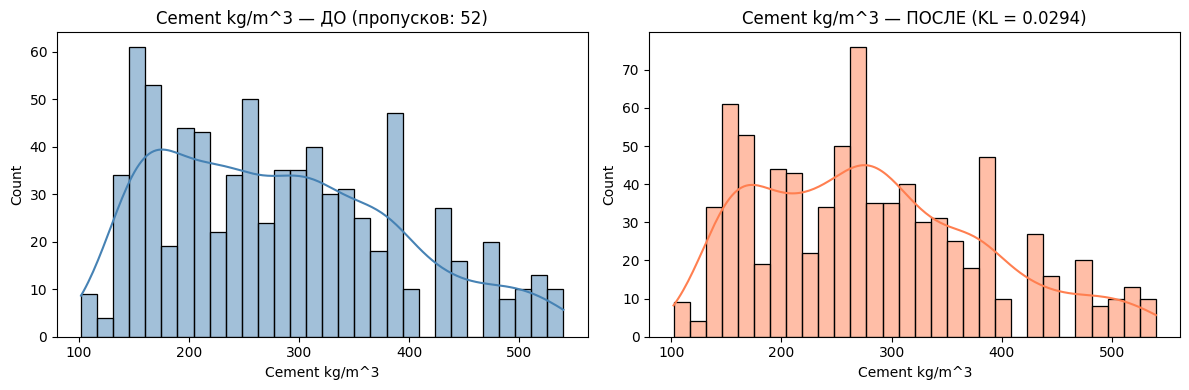

Cement kg/m^3: KL = 0.0294


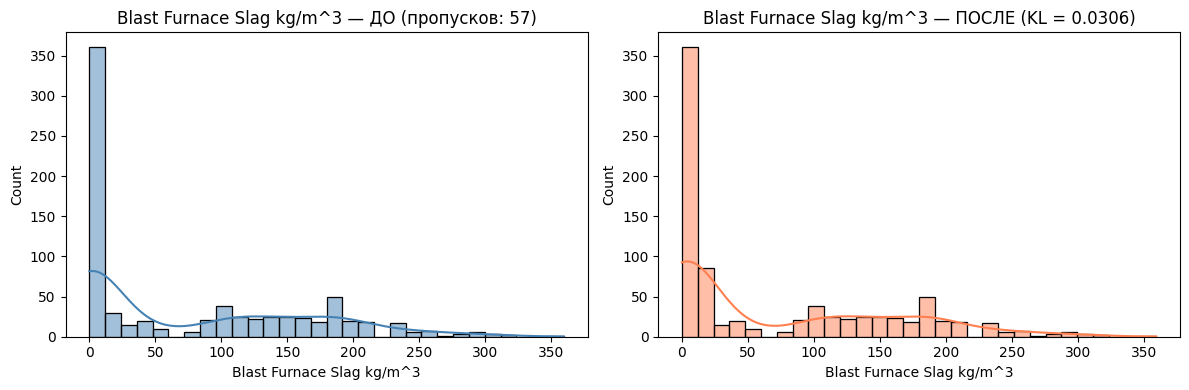

Blast Furnace Slag kg/m^3: KL = 0.0306


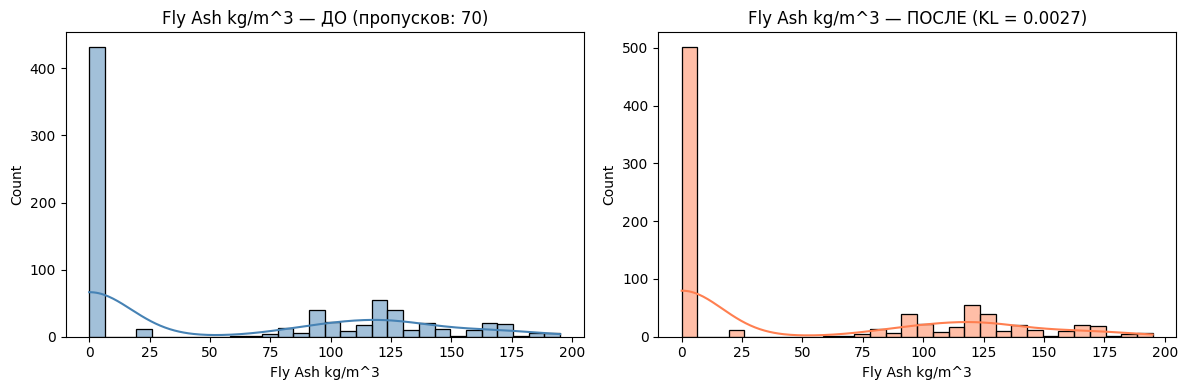

Fly Ash kg/m^3: KL = 0.0027


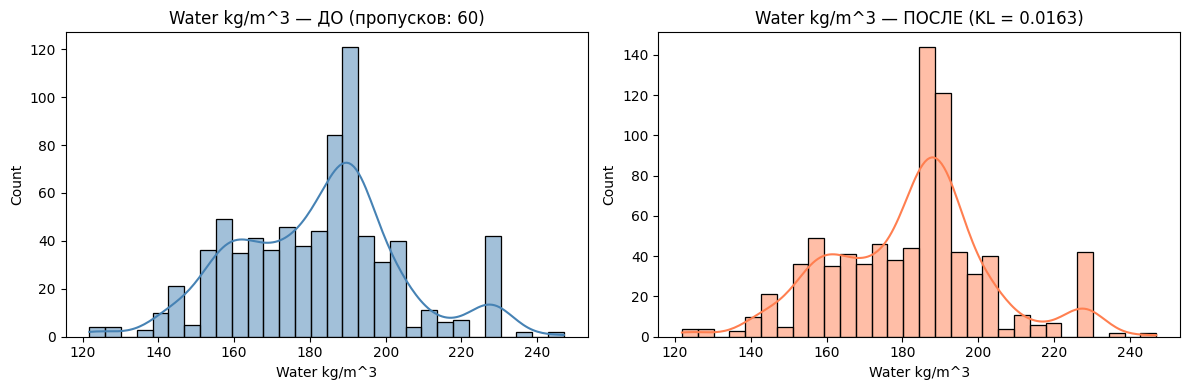

Water kg/m^3: KL = 0.0163


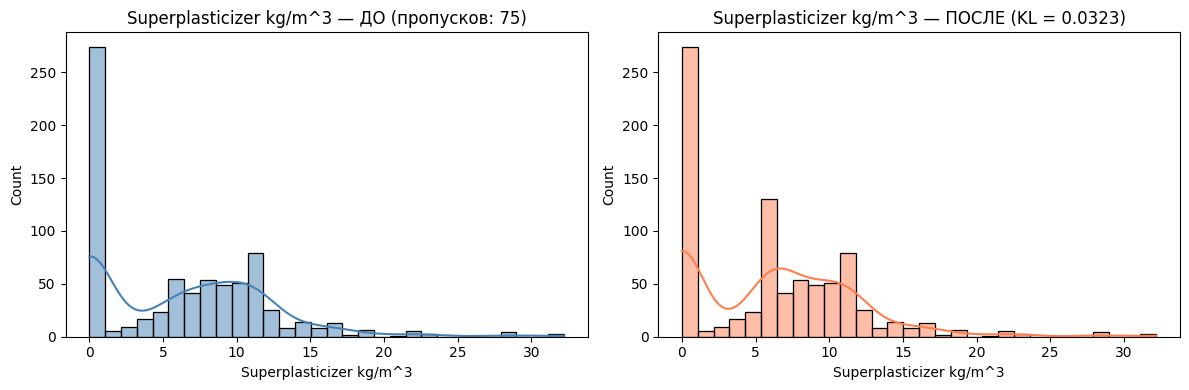

Superplasticizer kg/m^3: KL = 0.0323


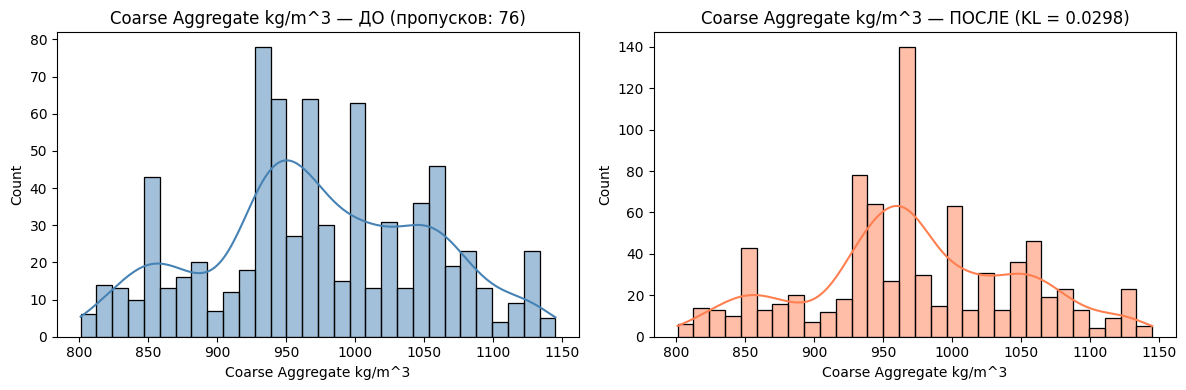

Coarse Aggregate kg/m^3: KL = 0.0298


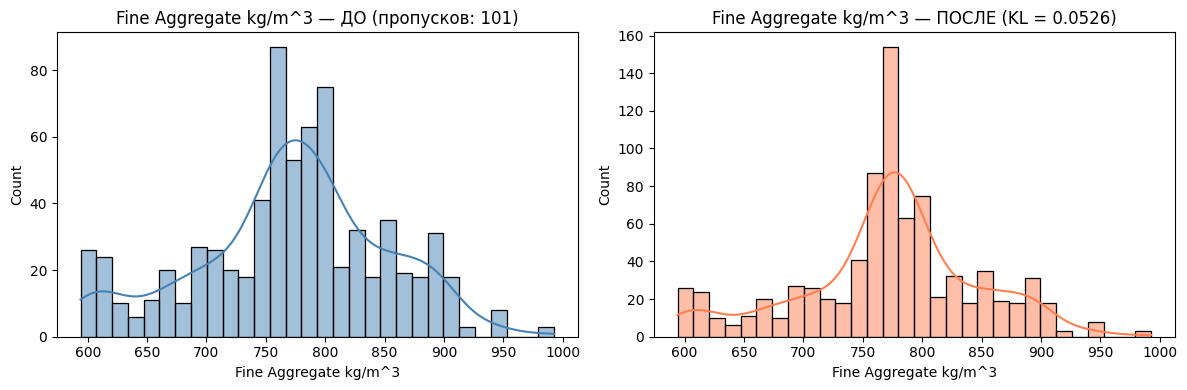

Fine Aggregate kg/m^3: KL = 0.0526


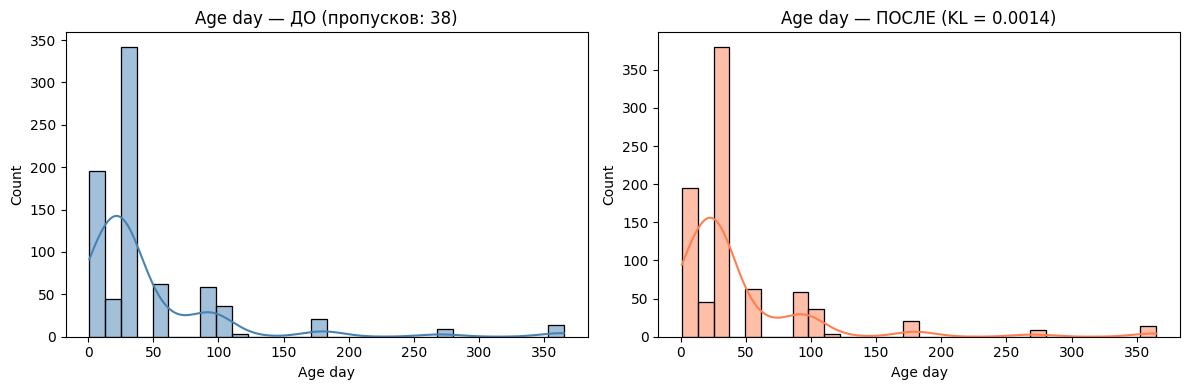

Age day: KL = 0.0014


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for col in xtrain_stat.select_dtypes(include='number').columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    before = X_train[col].dropna()
    after  = xtrain_stat[col]
    
    
    min_val = min(before.min(), after.min())
    max_val = max(before.max(), after.max())
    bin_edges = np.linspace(min_val, max_val, 31)  
    
    # строим частотные гистограммы и считаем вероятности
    hist_before, _ = np.histogram(before, bins=bin_edges)
    hist_after,  _ = np.histogram(after,  bins=bin_edges)
    
    p = hist_before / hist_before.sum()
    q = hist_after  / hist_after.sum()
    
    
    mask = (p > 0) & (q > 0)
    p_masked = p[mask]
    q_masked = q[mask]
    
    
    kl = np.sum(p_masked * np.log(p_masked / q_masked))
    
    
    sns.histplot(before, bins=30, kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col} — ДО (пропусков: {X_train[col].isnull().sum()})')
    
    sns.histplot(after, bins=30, kde=True, ax=axes[1], color='coral')
    axes[1].set_title(f'{col} — ПОСЛЕ (KL = {kl:.4f})')
    
    plt.tight_layout()
    plt.show()
    
    print(f'{col}: KL = {kl:.4f}')

Исходя из полученных распределений до и после заполнения, видим, что показатель KL у каждого из признаков <= 0.05, это говорит о том, что стратегия заполнения пропусков почти не исказила распределения, импутация статистически корректна
Для четсности жксперимента попробуем заполнить средним значением:

In [18]:
xtrain_stat = X_train.copy()
xtest_stat = X_test.copy()

In [19]:
for col in xtrain_stat.select_dtypes(include='number').columns:
    median = xtrain_stat[col].mean()
    xtrain_stat[col] = xtrain_stat[col].fillna(median)
    xtest_stat[col] = xtest_stat[col].fillna(median)

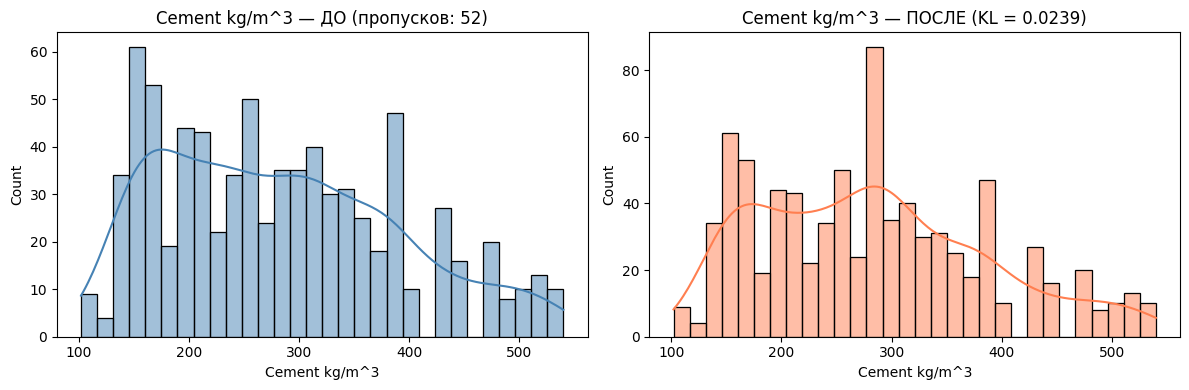

Cement kg/m^3: KL = 0.0239


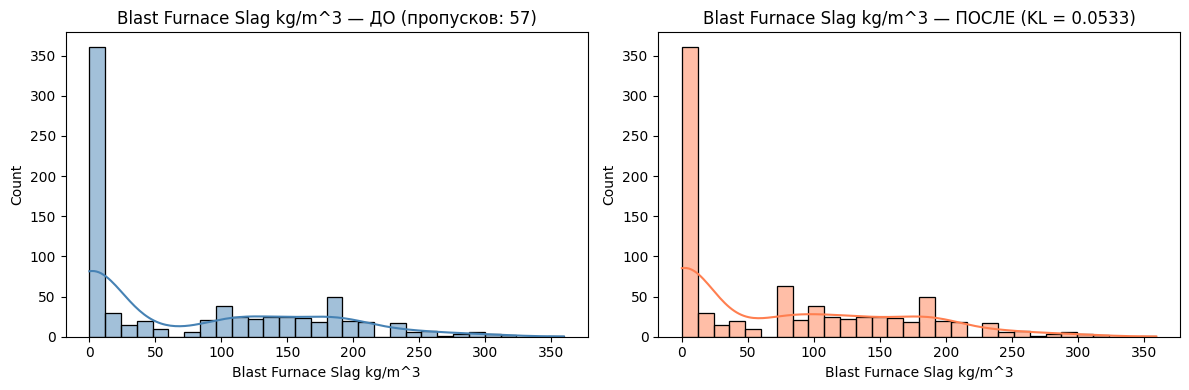

Blast Furnace Slag kg/m^3: KL = 0.0533


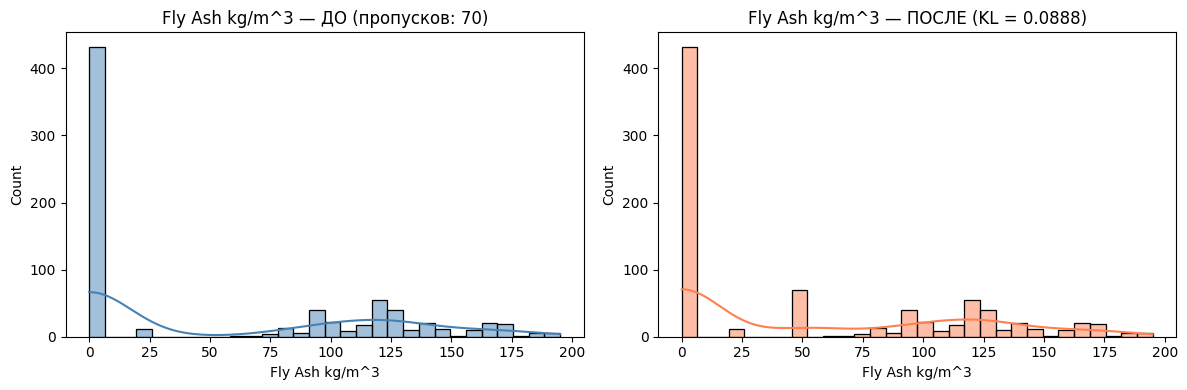

Fly Ash kg/m^3: KL = 0.0888


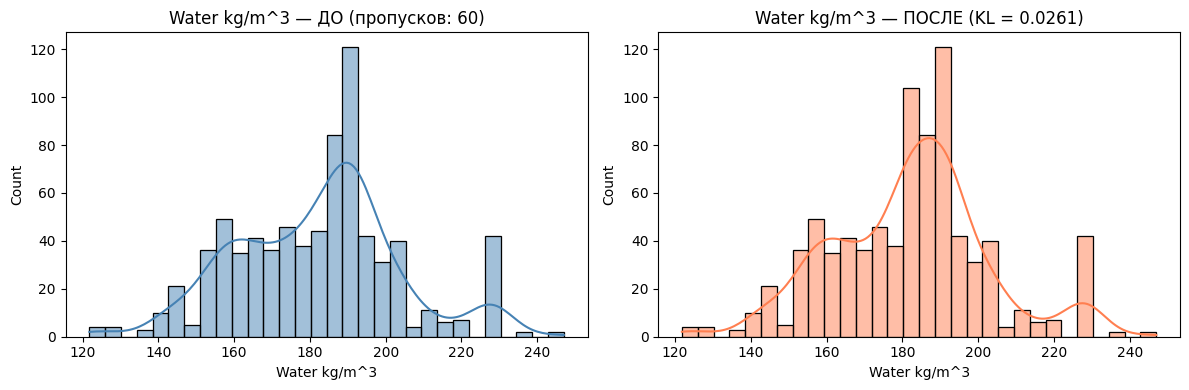

Water kg/m^3: KL = 0.0261


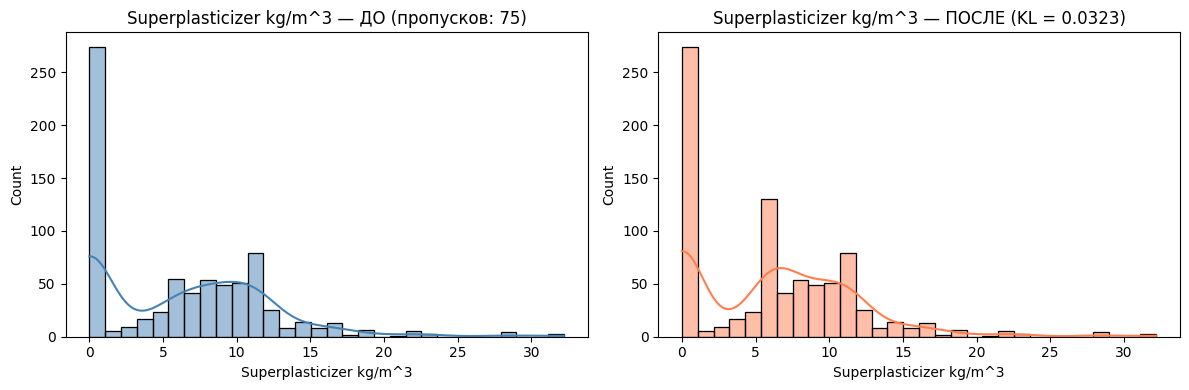

Superplasticizer kg/m^3: KL = 0.0323


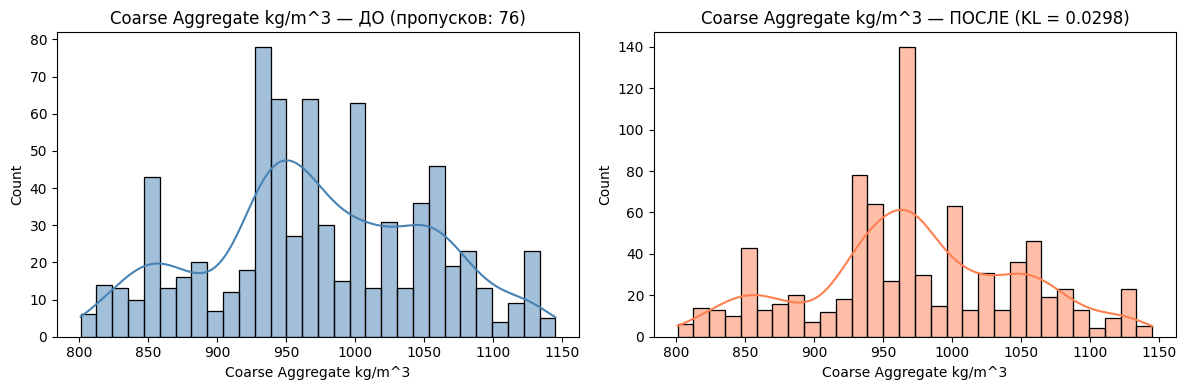

Coarse Aggregate kg/m^3: KL = 0.0298


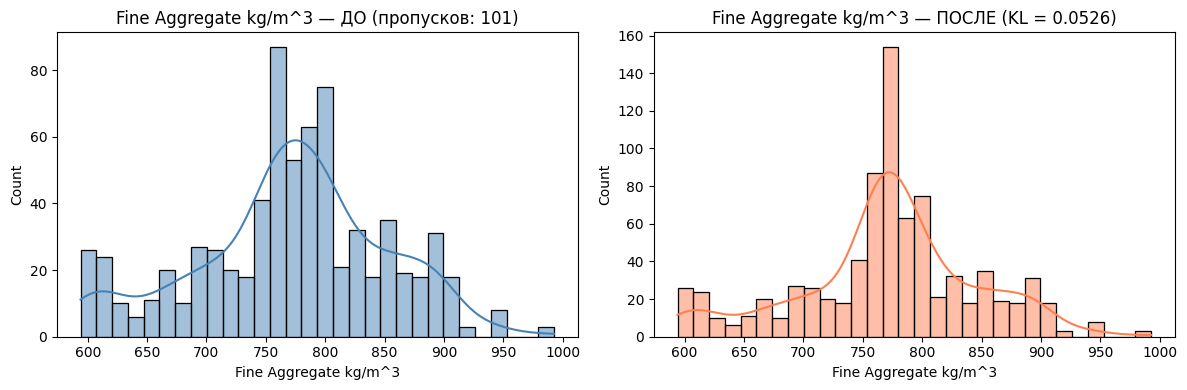

Fine Aggregate kg/m^3: KL = 0.0526


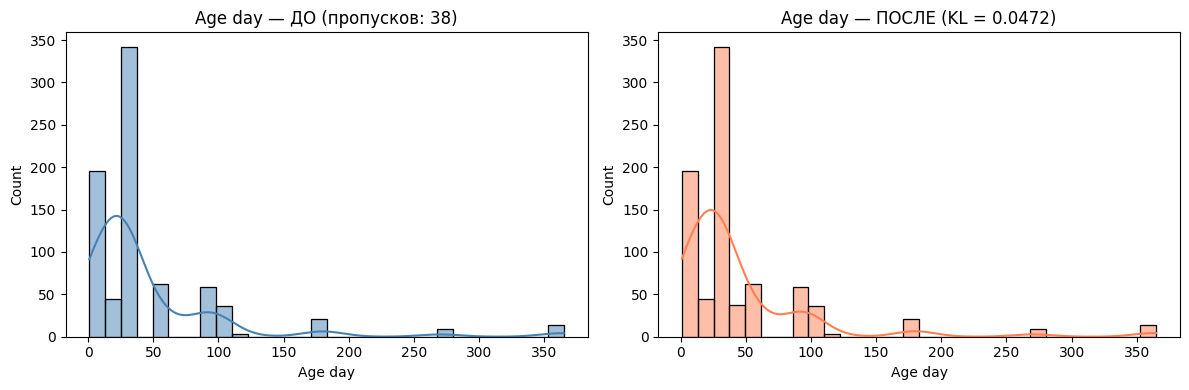

Age day: KL = 0.0472


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for col in xtrain_stat.select_dtypes(include='number').columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    before = X_train[col].dropna()
    after  = xtrain_stat[col]
    
    
    min_val = min(before.min(), after.min())
    max_val = max(before.max(), after.max())
    bin_edges = np.linspace(min_val, max_val, 31)  
    
    # строим частотные гистограммы и считаем вероятности
    hist_before, _ = np.histogram(before, bins=bin_edges)
    hist_after,  _ = np.histogram(after,  bins=bin_edges)
    
    p = hist_before / hist_before.sum()
    q = hist_after  / hist_after.sum()
    
    
    mask = (p > 0) & (q > 0)
    p_masked = p[mask]
    q_masked = q[mask]
    
    
    kl = np.sum(p_masked * np.log(p_masked / q_masked))
    
    
    sns.histplot(before, bins=30, kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col} — ДО (пропусков: {X_train[col].isnull().sum()})')
    
    sns.histplot(after, bins=30, kde=True, ax=axes[1], color='coral')
    axes[1].set_title(f'{col} — ПОСЛЕ (KL = {kl:.4f})')
    
    plt.tight_layout()
    plt.show()
    
    print(f'{col}: KL = {kl:.4f}')

Средним похуже, но все еще ок, однаком we`ll stick to медиана в этом кейсе


### Машинные подходы

In [33]:
xtrain_mach = X_train.copy()
xtest_mach = X_test.copy()

In [22]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


imputer_test = IterativeImputer(max_iter=100, random_state=42)
xtest_mach = pd.DataFrame(imputer_test.fit_transform(xtrain_mach), columns=xtrain_mach.columns)

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

nrmse = {}
for col in xtrain_stat.select_dtypes(include='number').columns:
    # Маска: True там, где значение БЫЛО (не NaN)
    known_mask = X_train[col].notna()
    
    true_vals   = X_train.loc[known_mask, col]
    filled_vals = xtrain_mach.loc[known_mask, col]
    
    mse  = mean_squared_error(true_vals, filled_vals)
    rmse = np.sqrt(mse)
    nrmse[col] = rmse / X_train[col].std()

print("NRMSE по колонкам:")
for col, val in nrmse.items():
    print(f"{col}: {val:.3f}")

NRMSE по колонкам:
Cement kg/m^3: 0.000
Blast Furnace Slag kg/m^3: 0.000
Fly Ash kg/m^3: 0.000
Water kg/m^3: 0.000
Superplasticizer kg/m^3: 0.000
Coarse Aggregate kg/m^3: 0.000
Fine Aggregate kg/m^3: 0.000
Age day: 0.000


In [34]:
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor


rf = RandomForestRegressor()

# берем данные, где нет пропусков
numeric_train = X_train.select_dtypes(include='number')
data_true = numeric_train.dropna().copy()




nan_columns = [col for col in numeric_train.columns if numeric_train[col].isnull().any()]

# искусственная генерация пропусков
np.random.seed(42)
mask = np.zeros(data_true.shape, dtype=bool)

for col in nan_columns:
    col_idx = data_true.columns.get_loc(col)
    col_mask = np.random.rand(len(data_true)) < 0.2
    mask[:, col_idx] = col_mask

data_masked = data_true.copy()
data_masked[mask] = np.nan


imputer = IterativeImputer(max_iter=100, random_state=42, estimator=rf)
data_filled = pd.DataFrame(
    imputer.fit_transform(data_masked),
    columns=data_masked.columns,
    index=data_masked.index
)


nrmse = {}
for col in nan_columns:
    col_idx = data_true.columns.get_loc(col)
    col_mask = mask[:, col_idx]
    
    if col_mask.sum() == 0:
        continue
    
    true_vals   = data_true.loc[col_mask, col]
    filled_vals = data_filled.loc[col_mask, col]
    
    mse  = mean_squared_error(true_vals, filled_vals)
    rmse = np.sqrt(mse)
    nrmse[col] = rmse / data_true[col].std()

print("NRMSE по колонкам:")
for col, val in nrmse.items():
    print(f"{col}: {val:.3f}")

NRMSE по колонкам:


Ну это очень плохо... Начальство не оценит, так что заполним медианой и не будем выпендриваться

In [25]:
for col in X_train.select_dtypes(include='number').columns:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

## 2.2 Кодирование категориальных признаков

Категориальных признаков у нас нет, ТРОЕКРРРАТНОЕ УРРА!

## ЛР 3. Детекция выбросов и аномалий в данных

## 1.6. Детекция выбросов и аномалий в данных

## 1.7. Подведение итогов раздела 1
<!-- А таких разделах обычно подытоживается вся информация о тех действиях, которые вы делали в разделе -->

# 2. Генерация новых признаков

## 2.1. Корреляционный анализ входных признаков (построение тепловых карт корреляции)

## 2.2. Исправление проблемы мультиколлинеарности в данных

## 2.3. Скалирование данных

## 2.4. Подведение итогов раздела 2
<!-- А таких разделах обычно подытоживается вся информация о тех действиях, которые вы делали в разделе -->

# 3. Выбор моделей ML и метрик

`ячейки для выбора моделей ML`
<!-- Третий раздел самый богатый на писанину. Вам необходимо сначала обосновать выбор моделей, а затем все отобранные модели описать (расписать концептуально, как они работают) -->

`ячейки для выбора метрик`
<!-- И снова писанина: необходимо не только описать, какие метрики вы используете, но привести формулы их вычисления -->

In [26]:
# ячейка для импорта моделей из пула

In [27]:
# ячейки для формирования сеток гиперпараметров

In [28]:
# ячейка для импорта метрик из пула

# 4. Обучение моделей ML и подбор гиперпараметров

In [29]:
# ячейки для подбора гиперпараметров и обучения лучших моделей

# 5. Вычисление метрик на новых данных

In [30]:
# ячейки для вычисления метрик на лучших моделях и их сопоставление

# 6. Результат работы

`ячейка для подведения итогов по всей работе`
<!-- Тут обычно пишется, какая модель показала себя лучше, с какими метриками и рекомендуется ли ее выводить в прод -->